In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_excel("../data/Online Retail.xlsx")

In [3]:
df.shape

(541909, 8)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [5]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [6]:
df["InvoiceDate"].min(), df["InvoiceDate"].max()

(Timestamp('2010-12-01 08:26:00'), Timestamp('2011-12-09 12:50:00'))

In [7]:
df.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [8]:
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

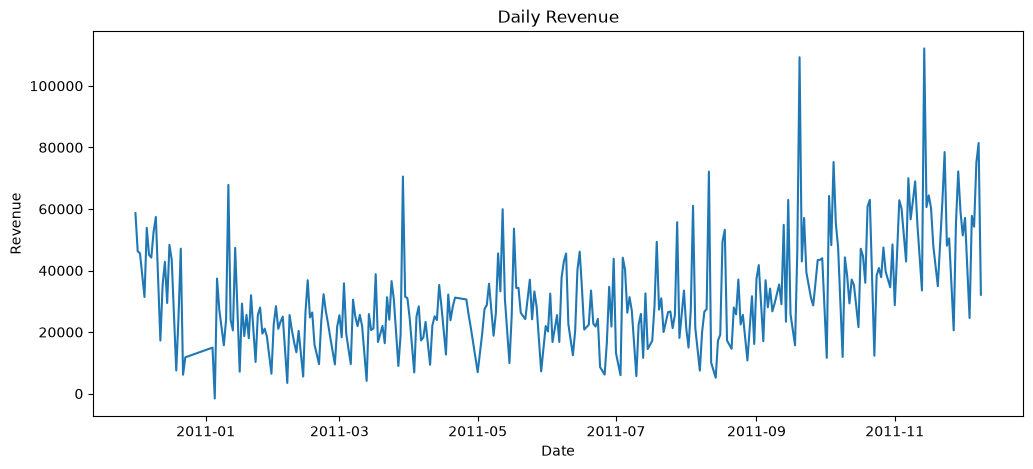

In [9]:
daily_revenue = df.groupby(
    df["InvoiceDate"].dt.date
)["Revenue"].sum()

daily_revenue.plot(figsize=(12, 5))

plt.xlabel("Date")
plt.ylabel("Revenue")
plt.title("Daily Revenue")
plt.show()

clean + create the time split

In [10]:
df = df.dropna(subset=["CustomerID"])

In [11]:
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]

In [12]:
df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
]

In [13]:
print(df.shape)
print(df["CustomerID"].nunique())

(397884, 9)
4338


In [14]:
cutoff_date = pd.Timestamp("2011-10-31")

In [15]:
past = df[df["InvoiceDate"] <= cutoff_date].copy()

future = df[
    (df["InvoiceDate"] > cutoff_date) &
    (df["InvoiceDate"] <= cutoff_date + pd.Timedelta(days=30))
].copy()

In [16]:
print("Past:", past["InvoiceDate"].min(), "→", past["InvoiceDate"].max())
print("Future:", future["InvoiceDate"].min(), "→", future["InvoiceDate"].max())

Past: 2010-12-01 08:26:00 → 2011-10-30 16:17:00
Future: 2011-10-31 08:29:00 → 2011-11-29 18:14:00


Build Customer Features

In [17]:
feature_start = cutoff_date - pd.Timedelta(days=90)

history = past[
    past["InvoiceDate"] >= feature_start
].copy()

In [18]:
history["InvoiceDate"].min(), history["InvoiceDate"].max()

(Timestamp('2011-08-02 08:48:00'), Timestamp('2011-10-30 16:17:00'))

In [19]:
features = history.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x:
             (cutoff_date - x.max()).days),

    Frequency=("InvoiceNo", "nunique"),

    TotalQuantity=("Quantity", "sum"),

    TotalRevenue=("Revenue", "sum"),

    AvgOrderValue=("Revenue", "mean"),

    UniqueProducts=("StockCode", "nunique")
).reset_index()

In [20]:
features.head()

,CustomerID,Recency,Frequency,TotalQuantity,TotalRevenue,AvgOrderValue,UniqueProducts
0,12347.0,89,1,277,584.91,26.586818,22
1,12348.0,35,1,217,310.00,103.333333,3
2,12352.0,32,2,155,632.50,19.765625,27
3,12359.0,17,1,657,2876.85,27.398571,100
4,12360.0,12,2,731,1578.48,18.791429,77


In [21]:
features.shape

(2453, 7)

In [22]:
target = future.groupby("CustomerID").agg(
    FutureRevenue=("Revenue", "sum")
).reset_index()

In [23]:
target.head()

,CustomerID,FutureRevenue
0,12347.0,1294.32
1,12349.0,1757.55
2,12352.0,311.73
3,12356.0,58.35
4,12357.0,6207.67


In [24]:
data = features.merge(
    target,
    on="CustomerID",
    how="left"
)

In [25]:
data["FutureRevenue"] = data["FutureRevenue"].fillna(0)

In [26]:
data.head()

,CustomerID,Recency,Frequency,TotalQuantity,TotalRevenue,AvgOrderValue,UniqueProducts,FutureRevenue
0,12347.0,89,1,277,584.91,26.586818,22,1294.32
1,12348.0,35,1,217,310.00,103.333333,3,0.00
2,12352.0,32,2,155,632.50,19.765625,27,311.73
3,12359.0,17,1,657,2876.85,27.398571,100,0.00
4,12360.0,12,2,731,1578.48,18.791429,77,0.00


In [27]:
data.shape

(2453, 8)

Prepare Data + Train/Test Split

In [28]:
data.corr(numeric_only=True)

,CustomerID,Recency,Frequency,TotalQuantity,TotalRevenue,AvgOrderValue,UniqueProducts,FutureRevenue
CustomerID,1.000000,-0.027792,0.006247,-0.012382,-0.002427,0.029595,-0.005767,-0.005147
Recency,-0.027792,1.000000,-0.267648,-0.125905,-0.119678,0.045608,-0.228950,-0.106511
Frequency,0.006247,-0.267648,1.000000,0.603586,0.590411,0.098197,0.639220,0.577655
TotalQuantity,-0.012382,-0.125905,0.603586,1.000000,0.914404,0.234597,0.423636,0.702360
TotalRevenue,-0.002427,-0.119678,0.590411,0.914404,1.000000,0.273990,0.381055,0.759523
AvgOrderValue,0.029595,0.045608,0.098197,0.234597,0.273990,1.000000,-0.110358,0.207393
UniqueProducts,-0.005767,-0.228950,0.639220,0.423636,0.381055,-0.110358,1.000000,0.501658
FutureRevenue,-0.005147,-0.106511,0.577655,0.702360,0.759523,0.207393,0.501658,1.000000


In [29]:
X = data[
    [
        "Recency",
        "Frequency",
        "TotalQuantity",
        "TotalRevenue",
        "AvgOrderValue",
        "UniqueProducts"
    ]
]

y = data["FutureRevenue"]

In [30]:
print(X.shape)
print(y.shape)

(2453, 6)
(2453,)


In [31]:
X.head()

,Recency,Frequency,TotalQuantity,TotalRevenue,AvgOrderValue,UniqueProducts
0,89,1,277,584.91,26.586818,22
1,35,1,217,310.00,103.333333,3
2,32,2,155,632.50,19.765625,27
3,17,1,657,2876.85,27.398571,100
4,12,2,731,1578.48,18.791429,77


In [32]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [33]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](6,)","[ 2.43,20.73,-0.39, 0.45, 0.44, 6.69]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](6,)","['Recency','Frequency','TotalQuantity','TotalRevenue','AvgOrderValue', 'UniqueProducts']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-263.2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(6)


In [34]:
y_pred = model.predict(X_test)

In [35]:
y_pred[:10]

array([ 700.3680846 ,  -89.19098946,  -43.98760867,  586.77650574,
        -57.01089642, -194.00075474,  704.60456209, -133.22427295,
        160.91329897,   33.11994036])

In [36]:
for feature, coef in zip(X.columns, model.coef_):
    print(f"{feature}: {coef:.2f}")

Recency: 2.43
Frequency: 20.73
TotalQuantity: -0.39
TotalRevenue: 0.45
AvgOrderValue: 0.44
UniqueProducts: 6.69


In [37]:
print("Intercept:", model.intercept_)

Intercept: -263.19796480014935


In [38]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [39]:
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

MAE : 374.08169714503873
RMSE: 1239.3082991328185
R²  : 0.2993165879019901


In [40]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

results.head(10)

,Actual,Predicted
0,495.00,700.368085
1,0.00,-89.190989
2,88.25,-43.987609
3,601.67,586.776506
4,71.00,-57.010896
5,0.00,-194.000755
6,0.00,704.604562
7,0.00,-133.224273
8,769.00,160.913299
9,0.00,33.119940


In [41]:
results["Error"] = (
    results["Actual"] - results["Predicted"]
)

results["AbsoluteError"] = results["Error"].abs()

results.head(10)

,Actual,Predicted,Error,AbsoluteError
0,495.00,700.368085,-205.368085,205.368085
1,0.00,-89.190989,89.190989,89.190989
2,88.25,-43.987609,132.237609,132.237609
3,601.67,586.776506,14.893494,14.893494
4,71.00,-57.010896,128.010896,128.010896
5,0.00,-194.000755,194.000755,194.000755
6,0.00,704.604562,-704.604562,704.604562
7,0.00,-133.224273,133.224273,133.224273
8,769.00,160.913299,608.086701,608.086701
9,0.00,33.119940,-33.119940,33.119940


Visualize & Diagnose

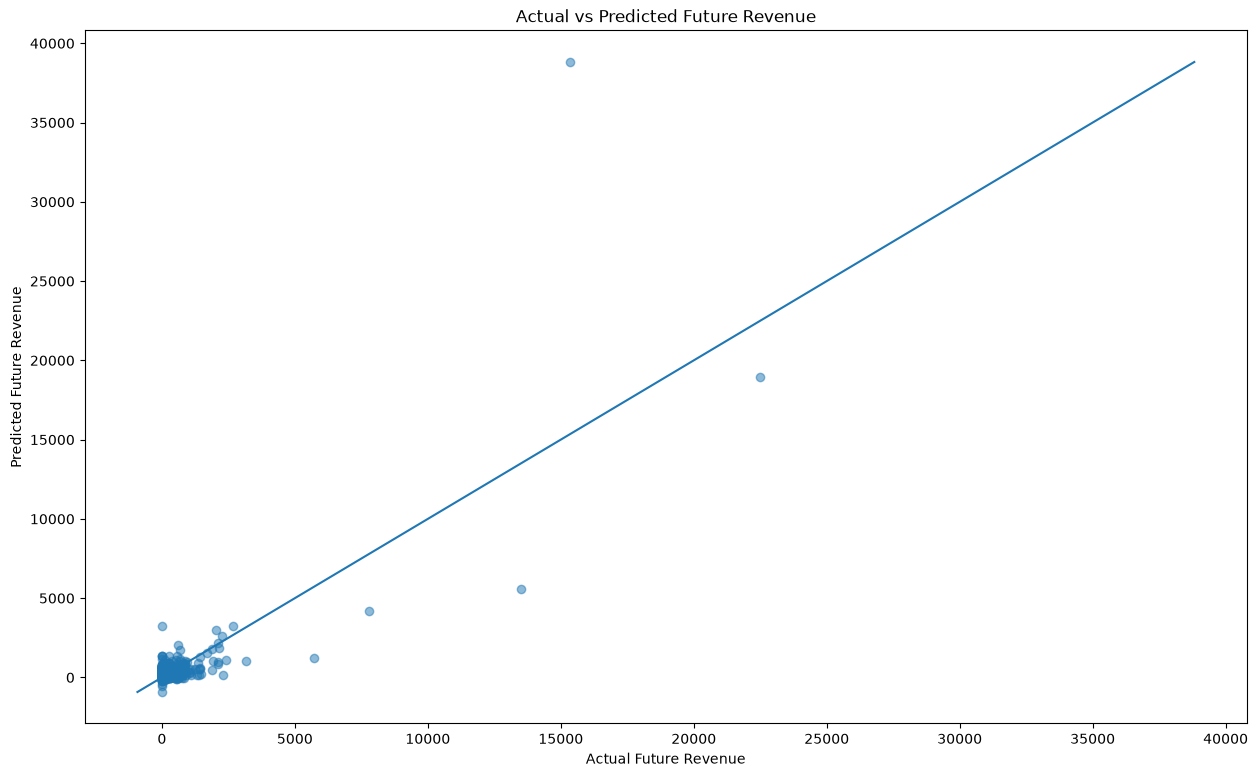

In [49]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 9))

plt.scatter(y_test, y_pred, alpha=0.5)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value]
)

plt.xlabel("Actual Future Revenue")
plt.ylabel("Predicted Future Revenue")
plt.title("Actual vs Predicted Future Revenue")

plt.show()

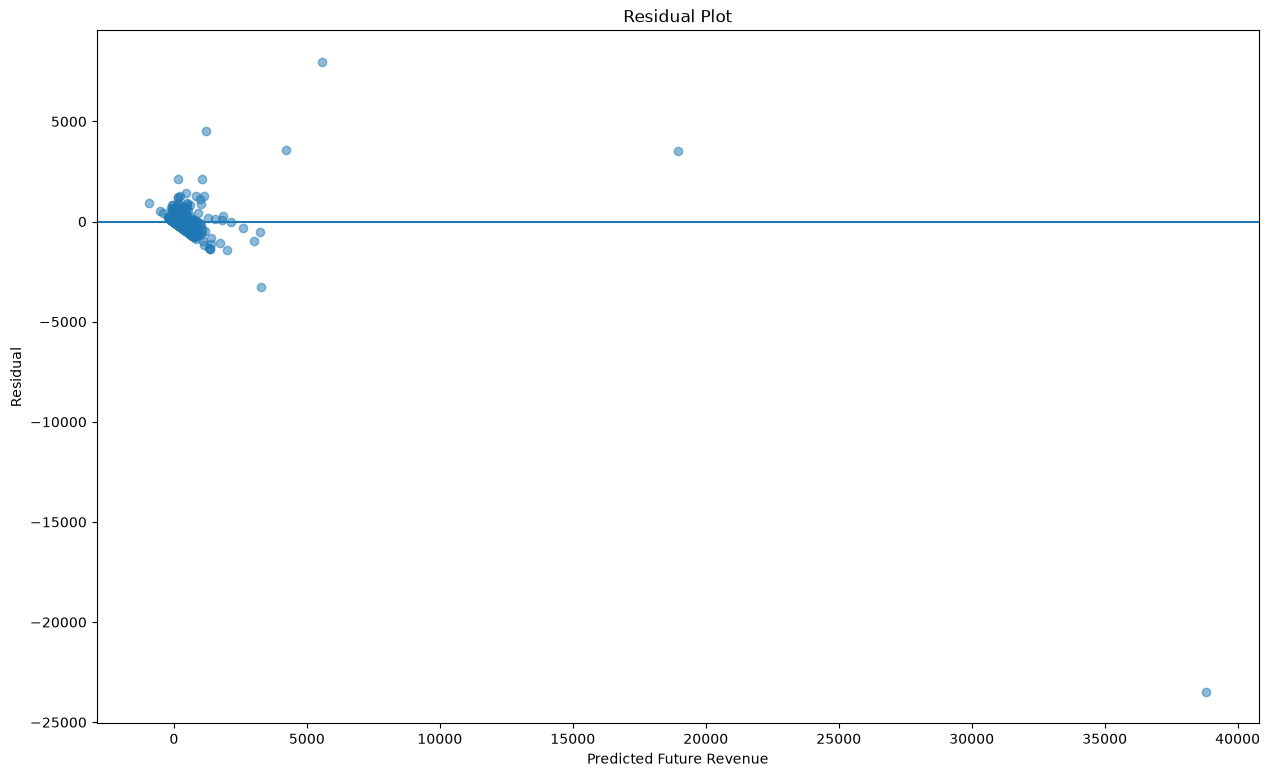

In [48]:
residuals = y_test - y_pred

plt.figure(figsize=(15, 9))

plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(0)

plt.xlabel("Predicted Future Revenue")
plt.ylabel("Residual")
plt.title("Residual Plot")

plt.show()

In [44]:
results["AbsoluteError"] = (
    results["Actual"] - results["Predicted"]
).abs()

results.sort_values(
    "AbsoluteError",
    ascending=False
).head(10)

,Actual,Predicted,Error,AbsoluteError
438,15331.08,38821.089293,-23490.009293,23490.009293
40,13522.22,5553.109313,7969.110687,7969.110687
378,5727.00,1211.848666,4515.151334,4515.151334
183,7779.70,4199.138246,3580.561754,3580.561754
360,22483.71,18957.161136,3526.548864,3526.548864
428,0.00,3262.332698,-3262.332698,3262.332698
293,3177.72,1045.310708,2132.409292,2132.409292
440,2298.72,170.068625,2128.651375,2128.651375
51,1876.10,459.418810,1416.681190,1416.681190
225,599.65,2013.997878,-1414.347878,1414.347878


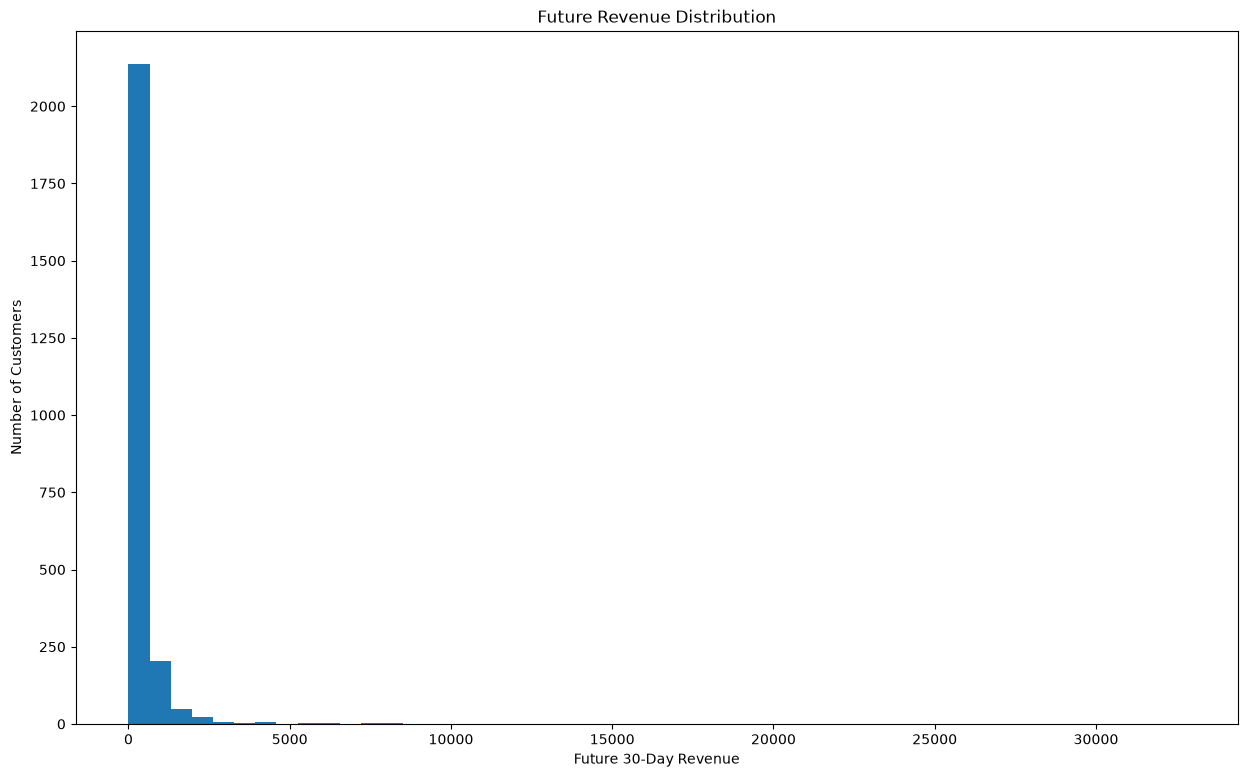

In [45]:
plt.figure(figsize=(15, 9))

plt.hist(data["FutureRevenue"], bins=50)

plt.xlabel("Future 30-Day Revenue")
plt.ylabel("Number of Customers")
plt.title("Future Revenue Distribution")

plt.show()

Improve the Model

Now we'll build a better Linear Regression pipeline and compare it with the original model.




In [46]:
# y_log = np.log1p(y)

In [47]:
# X_train, X_test, y_train, y_test = train_test_split(
#     X,
#     y_log,
#     test_size=0.2,
#     random_state=42
# )